In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/DataSet/ds05_wine.csv")
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [ ]:
print(df.shape)
print(df.info())
print(df.describe())

(178, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64


# 1. Wine Features (คุณสมบัติของไวน์)

* alcohol = ปริมาณแอลกอฮอล์
* malic_acid = ปริมาณกรดมาลิก
* ash = ปริมาณเถ้า
* alcalinity_of_ash = ค่าความเป็นด่างของเถ้า
* magnesium = ปริมาณแมกนีเซียม
* total_phenols = ปริมาณสารฟีนอลทั้งหมด
* flavanoids = ปริมาณสารฟลาโวนอยด์
* nonflavanoid_phenols = ปริมาณสารฟีนอลที่ไม่ใช่ฟลาโวนอยด์
* proanthocyanins = ปริมาณสารโปรแอนโทไซยานิดิน
* color_intensity = ความเข้มของสีไวน์
* hue = เฉดสีของไวน์
* od280/od315_of_diluted_wines = อัตราส่วนค่าการดูดกลืนแสง OD280/OD315 ของไวน์ที่เจือจาง
* proline = ปริมาณโพรลีน

# 2. Label (ตัวแปรเป้าหมาย)

* cultivar = ประเภทหรือสายพันธุ์ของไวน์
* 0 = ประเภทที่ 1
* 1 = ประเภทที่ 2
* 2 = ประเภทที่ 3

Accurancy:  1.0
Confusion Matrix: 
 [[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
Classification Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Result:  [0]


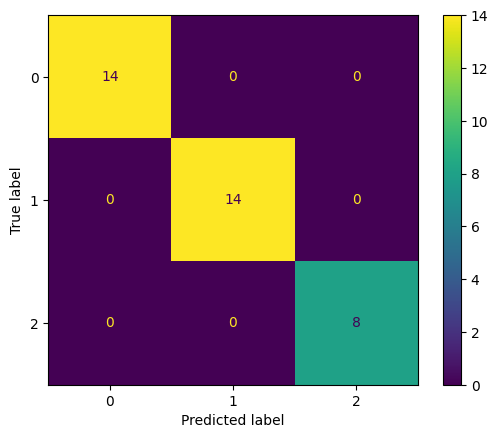

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

# Features
x = df.drop(columns=['cultivar'])

# Label
y = df['cultivar']

#Splilit Data
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

#ทำStandardization
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

Gaussian_model = GaussianNB()
Gaussian_model.fit(x_train,y_train)
y_pred = Gaussian_model.predict(x_test)
accuracy1 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy1)
confusion_matrix1 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix1)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display1 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=Gaussian_model.classes_)
matrix_display1.plot()

# Predict X (Wine)
result = Gaussian_model.predict(x_test[:1])
print("Result: ", result)


Accurancy:  1.0
Confusion Matrix: 
 [[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
Classification Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Result:  [0]


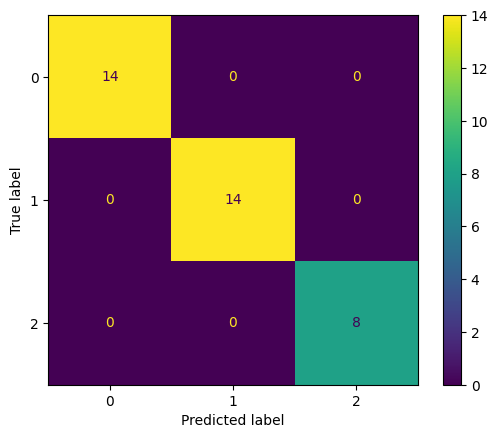

In [ ]:
#Classification with Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

Logistic_model = LogisticRegression()
Logistic_model.fit(x_train,y_train)
y_pred = Logistic_model.predict(x_test)
accuracy2 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy2)
confusion_matrix2 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix2)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display2 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=Logistic_model.classes_)
matrix_display2.plot()

# Predict X (Wine)
result = Logistic_model.predict(x_test[:1])
print("Result: ", result)

Accurancy:  1.0
Confusion Matrix: 
 [[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
Classification Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Result:  [0]


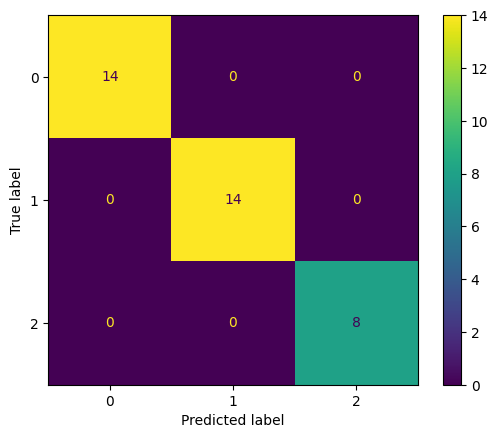

In [ ]:
 #Classification with SVM
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

SVM_model = SVC()
SVM_model.fit(x_train,y_train)
y_pred = SVM_model.predict(x_test)
accuracy3 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy3)
confusion_matrix3 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix3)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display3 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=SVM_model.classes_)
matrix_display3.plot()

# Predict X (Wine)
result = SVM_model.predict(x_test[:1])
print("Result: ", result)

Accurancy:  1.0
Confusion Matrix: 
 [[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
Classification Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Result:  [0]


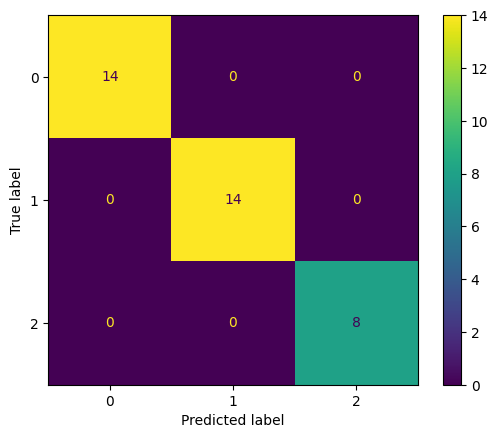

In [ ]:
#Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

forest_model = RandomForestClassifier()
forest_model.fit(x_train,y_train)
y_pred = forest_model.predict(x_test)
accuracy4 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy4)
confusion_matrix4 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix4)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display4 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=forest_model.classes_)
matrix_display4.plot()

# Predict X (Wine)
result = forest_model.predict(x_test[:1])
print("Result: ", result)

Accurancy:  0.9444444444444444
Confusion Matrix: 
 [[14  0  0]
 [ 1 12  1]
 [ 0  0  8]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.93      1.00      0.97        14
           1       1.00      0.86      0.92        14
           2       0.89      1.00      0.94         8

    accuracy                           0.94        36
   macro avg       0.94      0.95      0.94        36
weighted avg       0.95      0.94      0.94        36

Result:  [0]


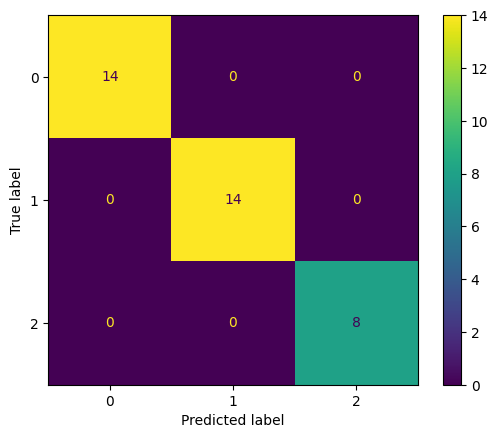

In [ ]:
#KNN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

KNN_model = KNeighborsClassifier()
KNN_model.fit(x_train,y_train)
y_pred = KNN_model.predict(x_test)
accuracy5 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy5)
confusion_matrix5 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix5)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display5 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=KNN_model.classes_)
matrix_display5.plot()

# Predict X (Wine)
result = KNN_model.predict(x_test[:1])
print("Result: ", result)

Accurancy:  1.0
Confusion Matrix: 
 [[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]
Classification Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Result:  [0]


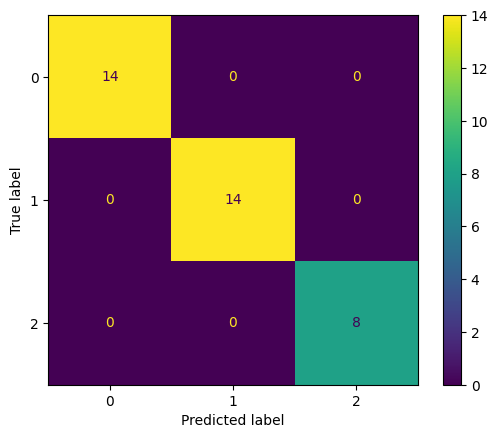

In [ ]:
#Nerual Network
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

Nerual_model = MLPClassifier(
    hidden_layer_sizes=(20,10),
    activation='relu',
    solver='adam',
    max_iter=500,
    random_state=42
)
Nerual_model.fit(x_train,y_train)
y_pred = Nerual_model.predict(x_test)
accuracy6 = accuracy_score(y_test,y_pred)
print("Accurancy: ",accuracy6)
confusion_matrix6 = confusion_matrix(y_test,y_pred)
print("Confusion Matrix: \n",confusion_matrix6)
print("Classification Report: \n",classification_report(y_test,y_pred))
matrix_display6 = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix1,display_labels=Nerual_model.classes_)
matrix_display6.plot()

# Predict X (Wine)
result = Nerual_model.predict(x_test[:1])
print("Result: ", result)

In [ ]:
#เปรียบเทียบโมเดลเพื่อหาว่าโมเดลใดเหมาะกับข้อมูล Loan
print("Accurancy of Neive Bayes: ",accuracy1)
print("Accurancy of Logistic Regression: ",accuracy2)
print("Accurancy of SVM: ",accuracy3)
print("Accurancy of Random Forest: ",accuracy4)
print("Accurancy of KNN: ",accuracy5)
print("Accurancy of Nerual Network: ",accuracy6)
print("----------------------------------------------------------")

def f1_score(tp,fp,fn):
  precision_score = tp/(tp+fp)
  recall_score = tp/(tp+fn)
  f1_score = 2*(precision_score*recall_score)/(precision_score+recall_score)
  return f1_score

#f1-naive bayes
tn,fp,fn,tp = confusion_matrix1[0,0],confusion_matrix1[0,1],confusion_matrix1[1,0],confusion_matrix1[1,1]
f1_nb = f1_score(tp,fp,fn)
print("f1-score of Neive Bayes: ",f1_nb)

#f1-logistic regression
tn,fp,fn,tp = confusion_matrix2[0,0],confusion_matrix2[0,1],confusion_matrix2[1,0],confusion_matrix2[1,1]
f1_lr = f1_score(tp,fp,fn)
print("f1-score of Logistic Regression: ",f1_lr)

#f1-svm
tn,fp,fn,tp = confusion_matrix3[0,0],confusion_matrix3[0,1],confusion_matrix3[1,0],confusion_matrix3[1,1]
f1_svm = f1_score(tp,fp,fn)
print("f1-score of SVM: ",f1_svm)

#f1-random forest
tn,fp,fn,tp = confusion_matrix4[0,0],confusion_matrix4[0,1],confusion_matrix4[1,0],confusion_matrix4[1,1]
f1_rf = f1_score(tp,fp,fn)
print("f1-score of Random Forest: ",f1_rf)

#f1-KNN
tn,fp,fn,tp = confusion_matrix5[0,0],confusion_matrix5[0,1],confusion_matrix5[1,0],confusion_matrix5[1,1]
f1_knn = f1_score(tp,fp,fn)
print("f1-score of KNN: ",f1_knn)

#f1-nerual network
tn,fp,fn,tp = confusion_matrix6[0,0],confusion_matrix6[0,1],confusion_matrix6[1,0],confusion_matrix6[1,1]
f1_nn = f1_score(tp,fp,fn)
print("f1-score of Nerual Network: ",f1_nn)

Accurancy of Neive Bayes:  1.0
Accurancy of Logistic Regression:  1.0
Accurancy of SVM:  1.0
Accurancy of Random Forest:  1.0
Accurancy of KNN:  0.9444444444444444
Accurancy of Nerual Network:  1.0
----------------------------------------------------------
f1-score of Neive Bayes:  1.0
f1-score of Logistic Regression:  1.0
f1-score of SVM:  1.0
f1-score of Random Forest:  1.0
f1-score of KNN:  0.9600000000000001
f1-score of Nerual Network:  1.0
